# h-means on small datasets

A hands-on comparison of **Lloyd's k-means**, **e-means** and **h-means** on datasets that ship with scikit-learn, so
everything here runs in seconds on a laptop with no download. The four contenders:

| method | what it is | budget |
|---|---|---|
| Lloyd | `sklearn.cluster.KMeans`, random rows as the start, full passes | the same number of passes as the mini-batch methods |
| k-means++ (converged) | `sklearn.cluster.KMeans` with the k-means++ seeding, run until it stops moving | unlimited, the reference |
| e-means | `hmeans.EMeans`, the mini-batch EMA method of Bessa et al. (Meta FAIR, 2025) | *n_passes* passes over the data |
| h-means | `hmeans.HMeans`, e-means plus a hierarchical warm start and Hartigan's assignment rule | the same *n_passes* |

The score is the k-means loss (`inertia_`, the sum of squared distances to the nearest centroid). Where the data has
labels we also report the adjusted Rand index and the normalised mutual information against them, but k-means is a
quantiser, not a classifier, and the loss is what the three methods optimise.

What to expect, in one line: with three clusters there is nothing to win and every method ties; the differences
appear when k is large relative to n, which is the regime h-means was built for.

One column to keep an eye on: `passes` is what each method actually spent, in units of n·k distance computations.
For h-means it includes the warm start, which is almost free at large k (the local refinement runs inside each
coarse cell) but costs about two extra passes when k is below 16, because the coarse level is then a single cell
and the refinement runs over all the data. At k = 3 the comparison is therefore not at equal budget, and the table
says so.

```
pip install "hmeans[sklearn] @ git+https://github.com/heldernoid/hmeans.git" matplotlib pandas
```

In [1]:
import time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris, load_wine, load_digits
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from hmeans import HMeans, EMeans

warnings.filterwarnings("ignore")
BACKEND = "numpy"   # "torch" runs on CPU, Apple MPS or CUDA; its start-up cost dominates on data this small
COLORS = {"Lloyd": "#2f855a", "k-means++ (converged)": "#8a8f98", "e-means": "#2b6cb0", "h-means": "#c8451f"}

In [2]:
def methods(k, n_passes, seed):
    """The four contenders for one seed. Lloyd, e-means and h-means get the same budget of passes over the
    data; k-means++ runs to convergence and is the reference, whatever it costs."""
    return {
        "Lloyd": KMeans(k, init="random", n_init=1, max_iter=n_passes, random_state=seed),
        "k-means++ (converged)": KMeans(k, init="k-means++", n_init=1, random_state=seed),
        "e-means": EMeans(k, n_passes=n_passes, backend=BACKEND, random_state=seed),
        "h-means": HMeans(k, n_passes=n_passes, backend=BACKEND, random_state=seed),
    }


def compare(X, k, n_passes=5, seeds=range(5), y=None, names=None):
    """Mean over seeds of the loss, the passes actually used (n·k distance computations, warm start included),
    the fit time, and the label agreement when y is given. The last column is the loss relative to e-means,
    negative is better. The ms column is not a fair speed comparison at this size: scikit-learn's Lloyd is
    compiled, the mini-batch methods run in NumPy and spend most of these milliseconds on overhead."""
    rows = []
    for seed in seeds:
        for name, m in methods(k, n_passes, seed).items():
            if names and name not in names:
                continue
            t = time.perf_counter(); m.fit(X); dt = time.perf_counter() - t
            row = {"method": name, "seed": seed, "inertia": m.inertia_, "passes": getattr(m, "n_passes_", m.n_iter_), "ms": 1000 * dt}
            if y is not None:
                row["ARI"] = adjusted_rand_score(y, m.labels_); row["NMI"] = normalized_mutual_info_score(y, m.labels_)
            rows.append(row)
    df = pd.DataFrame(rows)
    cols = {"inertia": ("inertia", "mean"), "sd": ("inertia", "std"), "passes": ("passes", "mean"), "ms": ("ms", "mean")}
    if y is not None:
        cols.update({"ARI": ("ARI", "mean"), "NMI": ("NMI", "mean")})
    agg = df.groupby("method", sort=False).agg(**cols)
    agg["vs e-means %"] = (agg["inertia"] / agg.loc["e-means", "inertia"] - 1) * 100
    return agg.round({"inertia": 1, "sd": 1, "passes": 1, "ms": 0, "ARI": 3, "NMI": 3, "vs e-means %": 2})


def scatter_panels(X, k, n_passes=5, seed=0, names=("Lloyd", "e-means", "h-means")):
    """The partition of each method on the first two principal components, centroids as crosses."""
    P = PCA(2).fit(X); Z = P.transform(X)
    fig, axes = plt.subplots(1, len(names), figsize=(4.2 * len(names), 4), sharex=True, sharey=True)
    for ax, name in zip(axes, names):
        m = methods(k, n_passes, seed)[name].fit(X); C = P.transform(m.cluster_centers_)
        ax.scatter(Z[:, 0], Z[:, 1], c=m.labels_, cmap="tab10", s=8, alpha=0.6)
        ax.scatter(C[:, 0], C[:, 1], c="k", marker="x", s=60, linewidths=1.5)
        ax.set_title(f"{name}: loss {m.inertia_:.1f}", color=COLORS[name]); ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); plt.show()

## Iris: three clusters, nothing to win

150 flowers, 4 measurements, 3 species. Standardised so that every feature counts the same. With k = 3 the problem is
tiny: every method lands on the same partition in a handful of passes, and h-means has no hierarchy to build (the
coarse level would be k/16 < 1 centroid), so it reduces to e-means plus Hartigan's rule. Expect a tie.

In [3]:
X_iris, y_iris = load_iris(return_X_y=True)
X_iris = StandardScaler().fit_transform(X_iris).astype(np.float32)
compare(X_iris, k=3, y=y_iris)

,inertia,sd,passes,ms,ARI,NMI,vs e-means %
method,,,,,,,
Lloyd,140.8,0.4,4.6,5.0,0.644,0.664,0.46
k-means++ (converged),140.3,0.6,4.6,2.0,0.634,0.663,0.13
e-means,140.1,0.5,5.0,12.0,0.620,0.656,0.00
h-means,139.8,0.0,7.5,34.0,0.620,0.659,-0.21


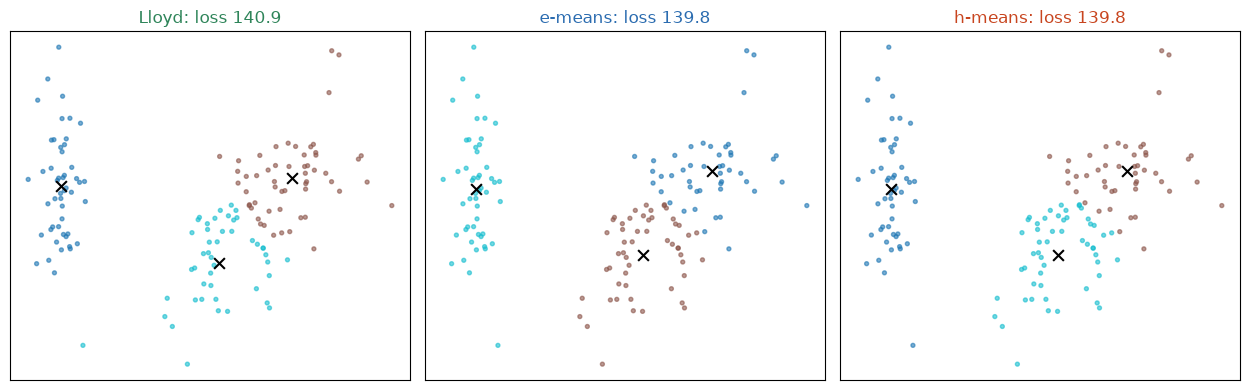

In [4]:
scatter_panels(X_iris, k=3)

The losses agree to a fraction of a percent, and the seeds that reach the slightly lower loss get the slightly
lower ARI. k-means separates setosa cleanly and splits versicolor and virginica along the longest axis of the cloud,
which is not where the species boundary is; a better optimiser finds a better split of the cloud, not a better
split of the species. That is a property of the loss, and no optimiser will fix it.

## Wine: 178 points, 13 features

Same story at k = 3. Pushing k to 10 (18 points per cluster) is the first place where the optimisers start to differ:
there are many local optima and few passes to find a good one.

In [5]:
X_wine, y_wine = load_wine(return_X_y=True)
X_wine = StandardScaler().fit_transform(X_wine).astype(np.float32)
display(compare(X_wine, k=3, y=y_wine))
compare(X_wine, k=10)

,inertia,sd,passes,ms,ARI,NMI,vs e-means %
method,,,,,,,
Lloyd,1312.7,70.0,5.0,2.0,0.806,0.812,2.68
k-means++ (converged),1278.5,0.9,5.8,2.0,0.898,0.876,0.01
e-means,1278.4,0.8,5.0,15.0,0.891,0.870,0.00
h-means,1277.9,0.0,7.5,23.0,0.897,0.876,-0.04


,inertia,sd,passes,ms,vs e-means %
method,,,,,
Lloyd,915.9,21.7,5.0,2.0,5.75
k-means++ (converged),888.0,30.2,9.4,3.0,2.53
e-means,866.1,16.1,5.0,15.0,0.00
h-means,862.6,14.5,7.2,34.0,-0.41


## Digits: 1,797 images of 8 × 8 pixels

The pixels are kept on their original scale (divided by 16) so that the centroids can be shown as images.
At k = 10, one centroid per digit, the methods are close; the centroid images show what each one found.

In [6]:
X_dig, y_dig = load_digits(return_X_y=True)
X_dig = (X_dig / 16).astype(np.float32)
compare(X_dig, k=10, y=y_dig)

,inertia,sd,passes,ms,ARI,NMI,vs e-means %
method,,,,,,,
Lloyd,4745.2,111.9,5.0,5.0,0.581,0.699,2.94
k-means++ (converged),4581.8,49.2,20.4,15.0,0.653,0.743,-0.60
e-means,4609.5,103.7,5.0,6.0,0.609,0.724,0.00
h-means,4584.4,32.9,7.1,11.0,0.615,0.728,-0.54


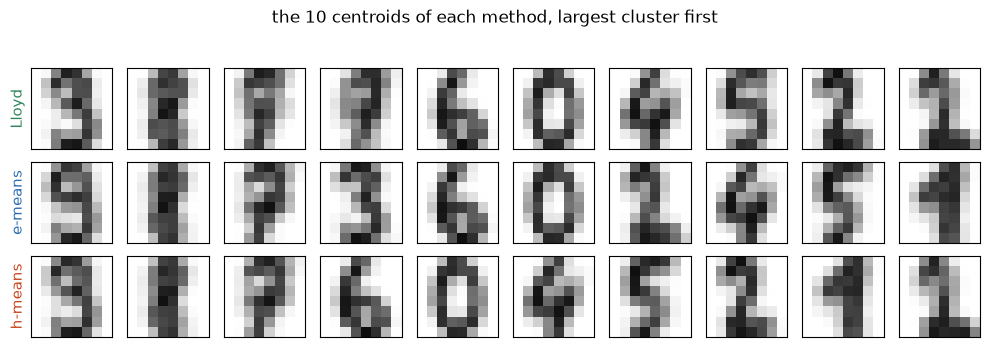

In [7]:
names = ["Lloyd", "e-means", "h-means"]
fig, axes = plt.subplots(len(names), 10, figsize=(10, 3.4))
for r, name in enumerate(names):
    m = methods(10, 5, 0)[name].fit(X_dig)
    order = np.argsort([-np.sum(m.labels_ == j) for j in range(10)])      # biggest cluster first
    for c, j in enumerate(order):
        ax = axes[r, c]; ax.imshow(m.cluster_centers_[j].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(name, color=COLORS[name], fontsize=11)
fig.suptitle("the 10 centroids of each method, largest cluster first", y=1.02); plt.tight_layout(); plt.show()

## The regime that matters: many clusters, few points per cluster

h-means was designed for vector quantisation, where k is in the thousands and each cluster holds a few dozen points.
Digits can imitate that regime by raising k. The plot shows the loss of every method relative to the converged
k-means++ reference as k grows, averaged over five seeds, with the budget of 5 passes for the three budgeted methods.

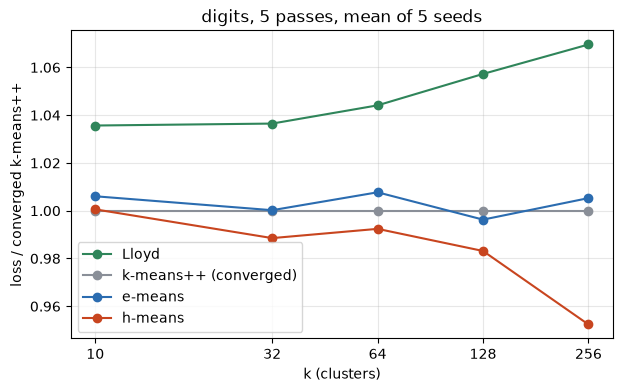

,inertia,sd,passes,ms,vs e-means %
method,,,,,
Lloyd,2182.6,26.6,5.0,6.0,6.12
k-means++ (converged),2064.4,6.9,10.8,26.0,0.37
e-means,2056.7,18.4,5.0,10.0,0.00
h-means,2029.6,11.5,5.6,21.0,-1.32


In [8]:
ks = [10, 32, 64, 128, 256]
rel = {name: [] for name in COLORS}
for k in ks:
    agg = compare(X_dig, k=k)
    for name in rel:
        rel[name].append(agg.loc[name, "inertia"] / agg.loc["k-means++ (converged)", "inertia"])
fig, ax = plt.subplots(figsize=(7, 4))
for name, v in rel.items():
    ax.plot(ks, v, "o-", color=COLORS[name], label=name)
ax.set_xscale("log", base=2); ax.set_xticks(ks); ax.set_xticklabels(ks)
ax.set_xlabel("k (clusters)"); ax.set_ylabel("loss / converged k-means++"); ax.set_title("digits, 5 passes, mean of 5 seeds")
ax.grid(alpha=0.3); ax.legend(); plt.show()
compare(X_dig, k=128)

Three things to read off the plot. Lloyd from random rows falls further behind the converged reference as k grows:
five full passes are not enough to sort out hundreds of centroids. e-means stays within about one percent of the
reference at every k from the same five passes, which is the e-means result in miniature. h-means goes below the
reference from k = 32 on and the margin widens with k. Below a converged run is possible because "converged" means
a local optimum of Lloyd's iteration from one k-means++ start; the warm start and Hartigan's rule simply reach a
better one, and the table at k = 128 shows the price in passes, well under one extra.

The passes sweep at k = 128 shows how the budget is spent. Lloyd plateaus early at the local optimum its random
start leads to and never reaches the reference. e-means crosses the reference line at about five passes, h-means
at two, and the gap between the two mini-batch methods persists at every budget.

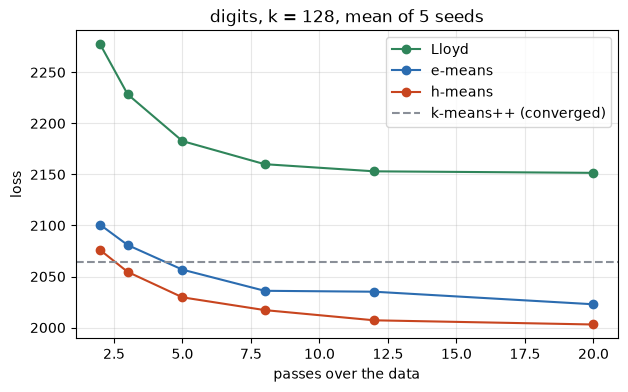

In [9]:
k = 128; Ts = [2, 3, 5, 8, 12, 20]
curves = {name: [] for name in ["Lloyd", "e-means", "h-means"]}
for T in Ts:
    agg = compare(X_dig, k=k, n_passes=T, names=curves)
    for name in curves:
        curves[name].append(agg.loc[name, "inertia"])
ref = compare(X_dig, k=k, names=["k-means++ (converged)", "e-means"]).loc["k-means++ (converged)", "inertia"]
fig, ax = plt.subplots(figsize=(7, 4))
for name, v in curves.items():
    ax.plot(Ts, v, "o-", color=COLORS[name], label=name)
ax.axhline(ref, color=COLORS["k-means++ (converged)"], ls="--", label="k-means++ (converged)")
ax.set_xlabel("passes over the data"); ax.set_ylabel("loss"); ax.set_title(f"digits, k = {k}, mean of 5 seeds")
ax.grid(alpha=0.3); ax.legend(); plt.show()

## Two dimensions: watch where the centroids go

The same toy as the front page of [h-means.github.io](https://h-means.github.io/): three Gaussians and uniform noise,
40,000 points, 800 centroids. Each centroid owns the region closest to it, its Voronoi cell, drawn here tinted by
area. Lloyd and e-means start from random rows, so 70% of their centroids land in the big Gaussian and never leave
it, because a centroid only ever moves to the mean of its own cell. h-means allocates the centroids of its
hierarchy in proportion to the loss, which hands the sparse noise far more of them. The titles count the centroids
inside the big Gaussian: same k, very different placement, and a much lower loss.

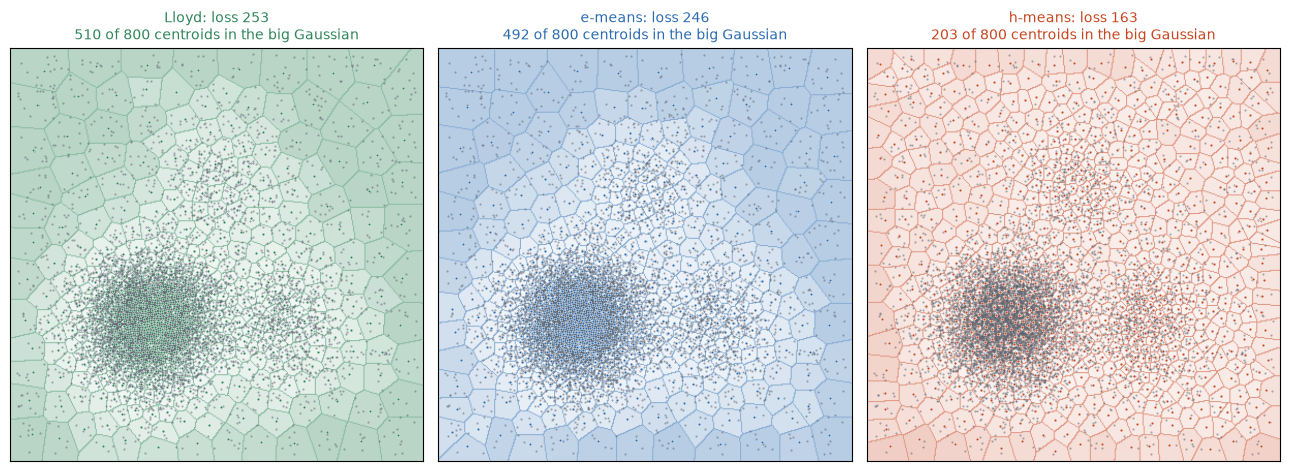

In [10]:
def three_gaussians(n, seed=0):
    rng = np.random.default_rng(seed)
    parts = np.round(np.array([0.7, 0.1, 0.05, 0.05]) * n).astype(int); parts[-1] = n - parts[:-1].sum()
    blobs = [rng.normal(c, 0.5, size=(m, 2)) for m, c in zip(parts[:3], [(-1, -1), (1, -1), (0, 1)])]
    noise = rng.uniform(-3, 3, size=(parts[3], 2))
    X = np.vstack(blobs + [noise]).astype(np.float32); return X[rng.permutation(n)]


def voronoi_panel(ax, X, m, name, color, res=400):
    from scipy.spatial import cKDTree
    C = m.cluster_centers_; lo, hi = -3.1, 3.1
    g = np.linspace(lo, hi, res); gx, gy = np.meshgrid(g, g)
    ids = cKDTree(C).query(np.c_[gx.ravel(), gy.ravel()])[1].reshape(res, res)
    area = np.bincount(ids.ravel(), minlength=len(C)); alpha = 0.04 + 0.3 * np.minimum(1, area[ids] / (6 * area.mean()))
    edge = np.zeros_like(ids, bool); edge[:, :-1] |= ids[:, :-1] != ids[:, 1:]; edge[:-1, :] |= ids[:-1, :] != ids[1:, :]
    alpha[edge] = 0.55
    rgb = np.array([int(color[i:i + 2], 16) / 255 for i in (1, 3, 5)])
    img = 1 - alpha[..., None] * (1 - rgb)
    ax.imshow(img, extent=(lo, hi, lo, hi), origin="lower", interpolation="bilinear")
    ax.scatter(X[:8000, 0], X[:8000, 1], s=0.3, c="#5c636e", alpha=0.5)
    ax.scatter(C[:, 0], C[:, 1], s=4, c=color, edgecolors="white", linewidths=0.3)
    inside = int(np.sum(np.hypot(C[:, 0] + 1, C[:, 1] + 1) < 1.1))
    ax.set_title(f"{name}: loss {m.inertia_:.0f}\n{inside} of {len(C)} centroids in the big Gaussian", color=color, fontsize=10)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_xticks([]); ax.set_yticks([])


X2 = three_gaussians(40_000); k2 = 800
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, name in zip(axes, ["Lloyd", "e-means", "h-means"]):
    m = methods(k2, 5, 0)[name]
    if name == "Lloyd":
        m.set_params(max_iter=25)       # Lloyd gets 25 full passes here, like the site
    voronoi_panel(ax, X2, m.fit(X2), name, COLORS[name])
plt.tight_layout(); plt.show()

The k-means optimum places centroids with a density proportional to the data density to the power d/(d+2), the
square root in two dimensions, so a region a thousand times sparser still deserves about a thirtieth of the centroid
density, far more than its share of random rows. Two dimensions exaggerate the effect, and the e-means laws were
not fitted there; on the 96- to 784-dimensional benchmarks of the [report](../REPORT.md) the gain is 2 to 7% at small
n/k and a tie at large n/k.

## Things to try

- Change `BACKEND` to `"torch"` for larger data; it uses CUDA or Apple MPS when available.
- `HMeans(..., warm_start=False)` or `hartigan_ema=False, tail=None` switch the two ingredients off one at a time.
- `ema_frac` sets the split between EMA passes and exact Hartigan passes; `"auto"` picks it from n/k.
- The [playground](https://h-means.github.io/playground) runs the same three methods in the browser on 2-D data.